# Patterns in Boston 311 Service Delays, 2023–2024
**BA777 · Cohort B · Team 8 (B08) · Phase 2 report**

Team: Almira, Ashwin, Eldo, Judy, Zoya

**Data and terms.** [Analyze Boston 311 service requests](https://data.boston.gov/dataset/311-service-requests) are available under the [Open Data Commons PDDL](https://opendatacommons.org/licenses/pddl/1-0/). Daily weather at [NOAA's Boston Logan station](https://www.ncdc.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:USW00014739/detail) is publicly available U.S. government data. Section 2 links to the CSVs. Section 3 gives the BigQuery access instructions.

**Notebook:** `B08-Patterns-in-Boston-311-Service-Delays.ipynb`. All analysis is BigQuery SQL run through `%%bigquery` cells; Python is used only to connect.

| # | Section | Owner |
|---|---|---|
| 1 | Business problem | Almira |
| 2 | Data and sources | Almira |
| 3 | BigQuery setup and source tables | Ashwin |
| 4 | Data quality and cleaning | Ashwin |
| 5 | Q1: Demand | Judy |
| 6 | Q2: Time to close and on-time rate | Ashwin |
| 7 | Q3: Neighborhood gaps, 2023 vs 2024 | Zoya |
| 8 | Q4: Weather vs volume and delays | Eldo |
| 9 | Conclusions and Phase 3 plan | Almira (with input from all) |
| 10 | References | Almira |
| 11 | Generative AI disclosure | Almira |

## Executive summary

Boston 311 managers can use this report to decide which service queues to audit and when to plan for more requests. We used BigQuery SQL to clean 614,546 cases opened in 2023 and 2024 and join them to daily weather at Logan Airport. Parking Enforcement accounted for about one in five cases, and request volume peaked in late summer in both years. Among cases with a target, 75.7% met it in 2023 and 72.0% in 2024, while closed Parking Enforcement cases in West Roxbury took about seven times as long to close as those in South Boston in 2023. Weather mattered less than the calendar: once weekdays are compared with weekdays, hot days brought only 2.6% more requests than normal days in the same months. We recommend checking open Transportation records against work logs and reviewing the parking gap before reassigning crews.

## 1. Business problem
*Owner: Almira*

Boston's 311 operations managers need to decide where to add capacity and which service queues to audit. Long closure times and missed targets can point to a backlog or a problem with how cases are recorded. We aim to identify the busiest periods, measure the share of targeted cases that meet their deadlines, and show where similar requests have consistently different closure times.

We look at four questions from the proposal.

1. **Demand.** What gets reported most, when does volume peak, and who files the requests?
2. **Speed.** How long do cases take to close, and which departments and request types miss their targets most often?
3. **Neighborhoods.** How much do closure times vary for the same request type, and do the gaps persist from 2023 to 2024?
4. **Weather.** How do volume and lateness on snow, heavy rain, hot and cold days compare with normal days in the same months?

We narrowed the weather question to four groups. Weather conditions cluster in particular months, so each group is compared with normal days in the same months.

**Success criteria.** The analysis succeeds if it gives managers (1) an on-time rate that only counts cases with a target, (2) a ranked list of departments and request types that miss targets most often, and (3) neighborhood and weather comparisons made within the same request type, month and kind of day.

**Takeaway.** Missed targets and long closure times show managers which queues to audit first. A close date records when the case was closed in the City's system, not necessarily when the work was finished, so we report *recorded* closure times.

## 2. Data and sources
*Owner: Almira*

| Dataset | Source | Rows | Columns | Size |
|---|---|---|---|---|
| 311 Service Requests 2023 | City of Boston, [Analyze Boston](https://data.boston.gov/dataset/311-service-requests) (provider: Boston 311, license: ODC PDDL) | 307,791 | 30 | 184 MB |
| 311 Service Requests 2024 | Same | 306,756 | 30 | 182 MB |
| Daily weather 2023–2024 | NOAA NCEI, GHCN-Daily, [Boston Logan station USW00014739](https://www.ncdc.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:USW00014739/detail), public U.S. government data, U.S. units | 731 | 44 | under 1 MB |

**311 requests.** One row per case (`case_enquiry_id`), with the date it was opened, the City's target date, the date it was closed, the request type, the department, how it was reported and where it is. The project uses the City files dated September 18, 2026. The files include closures recorded after the request year.

**Weather.** One row per day at Boston Logan Airport: precipitation, snowfall, high and low temperature, and wind, in inches, °F and mph. One station stands in for the whole city.

**How the tables connect.** The two 311 files are combined into one view, and each case gets the weather for the day it was opened (section 4.10).

**What we left out.** 2025 and 2026. The City moved 311 to a new system in October 2025, which splits those years across two datasets with different layouts.

| Download | Source filename |
|---|---|
| [Boston 311, 2023](https://data.boston.gov/dataset/8048697b-ad64-4bfc-b090-ee00169f2323/resource/e6013a93-1321-4f2a-bf91-8d8a02f1e62f/download/lagan_311_open_data_2023_rvsd3.csv) | `311_2023.csv` |
| [Boston 311, 2024](https://data.boston.gov/dataset/8048697b-ad64-4bfc-b090-ee00169f2323/resource/dff4d804-5031-443a-8409-8344efd0e5c8/download/lagan_311_open_data_2024_rvsd3.csv) | `311_service_request_2024.csv` |
| [NOAA Boston Logan, 2023–2024](https://www.ncei.noaa.gov/access/services/data/v1?dataset=daily-summaries&stations=USW00014739&startDate=2023-01-01&endDate=2024-12-31&dataTypes=AWND,PGTM,PRCP,SNOW,TAVG,TMAX,TMIN,WDF2,WDF5,WSF2,WSF5,WT01,WT02,WT03,WT04,WT05,WT06,WT08,WT09&units=standard&format=csv&includeAttributes=true&includeStationName=true&includeStationLocation=1) | `noaa_weather_data_2023~2024.csv` |

**Takeaway.** The two City files use the same layout. Opening date links each 311 case to daily weather at Logan, which is used as a citywide measure.

---
## 3. BigQuery setup and source tables
*Owner: Ashwin*

### 3.1 Connect to the project

The earlier notebook's BigQuery results show three persistent source tables in `ba777-apr.b08`. This report reads those tables directly with SQL and stores its daily weather table and views separately in `ba777-apr.b08_phase2_sql`.

1. Open [BigQuery Studio](https://console.cloud.google.com/bigquery?project=ba777-apr) with your course account. Select project `ba777-apr` and job location `US`. The account needs to run query jobs, read the `b08` dataset and create objects in the report dataset.
2. Use an authenticated Jupyter runtime with [BigQuery Magics](https://docs.cloud.google.com/python/docs/reference/bigquery/latest/magics) enabled. For a standard Colab runtime, run `from google.colab import auth` and `auth.authenticate_user()` in a temporary cell, then run `%load_ext bigquery_magics`. If the extension is missing, install it with `%pip install bigquery-magics` first. These commands only initialize the connection. Remove the temporary cell from the submission. If using BigQuery Studio's native SQL cells, run the SQL below each `%%bigquery` line.
3. Run the source-count check first. It should show `TRUE` for all three tables. If a table is missing, check the account, project and dataset location. The appendix has SQL to restage the source CSVs if needed.

Medians and 90th percentiles use BigQuery's `APPROX_QUANTILES`, which is approximate: a rounded percentile can differ by about 0.01 day from an exact calculation.

### 3.2 Check the existing raw tables

In [ ]:
%%bigquery --project ba777-apr
-- Confirm the three source tables loaded completely (expected counts from the source files).
WITH source_counts AS (
  SELECT 'raw_311_2023' AS table_name, COUNT(*) AS loaded_rows, 307791 AS expected_rows
  FROM `ba777-apr.b08.raw_311_2023`
  UNION ALL
  SELECT 'raw_311_2024', COUNT(*), 306756
  FROM `ba777-apr.b08.raw_311_2024`
  UNION ALL
  SELECT 'raw_weather', COUNT(*), 731
  FROM `ba777-apr.b08.raw_weather`
)
SELECT *, loaded_rows = expected_rows AS matches_report_snapshot
FROM source_counts
ORDER BY table_name;

table_name,loaded_rows,expected_rows,matches_report_snapshot
raw_311_2023,307791,307791,True
raw_311_2024,306756,306756,True
raw_weather,731,731,True


### 3.3 Create the report dataset and combine the two years

The source tables stay in `b08`. The raw 311 view adds the file year for auditing and matches the two tables' columns by name.

In [ ]:
%%bigquery --project ba777-apr
-- Create the report dataset that holds the weather table and views.
CREATE SCHEMA IF NOT EXISTS `ba777-apr.b08_phase2_sql`
OPTIONS(location = 'US');

In [ ]:
%%bigquery --project ba777-apr
-- Combine the 2023 and 2024 raw tables into one view, tagged with the file year.
CREATE OR REPLACE VIEW `ba777-apr.b08_phase2_sql.v_311_raw` AS
SELECT 2023 AS file_year, * FROM `ba777-apr.b08.raw_311_2023`
UNION ALL BY NAME
SELECT 2024 AS file_year, * FROM `ba777-apr.b08.raw_311_2024`;

**Takeaway.** The report uses 614,547 raw 311 records and 731 weather days.

---
## 4. Data quality and cleaning
*Owner: Ashwin*

Each check runs on the raw data and ends with a decision. Section 4.9 puts all the decisions into one cleaned view, `v_311_clean`, which every later section uses.

### 4.1 Row counts, duplicates and date range
**Check:** Did both files load completely, with each case once and in the right year?

In [ ]:
%%bigquery --project ba777-apr
-- Row counts, duplicate case IDs and opening-date range for each file year.
SELECT
  file_year,
  COUNT(*) AS row_count,
  COUNT(DISTINCT case_enquiry_id) AS distinct_case_ids,
  COUNT(*) - COUNT(DISTINCT case_enquiry_id) AS duplicate_case_ids,
  COUNTIF(SUBSTR(open_dt, 1, 4) != CAST(file_year AS STRING)) AS opened_in_another_year,
  MIN(open_dt) AS first_opened,
  MAX(open_dt) AS last_opened,
  MAX(closed_dt) AS last_closed
FROM `ba777-apr.b08_phase2_sql.v_311_raw`
GROUP BY file_year
ORDER BY file_year;

file_year,row_count,distinct_case_ids,duplicate_case_ids,opened_in_another_year,first_opened,last_opened,last_closed
2023,307791,307791,0,0.0,2023-01-01 00:11:22.94,2023-12-31 23:50:00,2026-09-16 13:16:40.27
2024,306756,306756,0,0.0,2024-01-01 00:20:52.963,2024-12-31 23:47:03.657,2026-09-11 08:09:10.853


In [ ]:
%%bigquery --project ba777-apr
-- Case IDs that appear in both the 2023 and the 2024 file
SELECT COUNT(*) AS case_ids_in_both_years
FROM `ba777-apr.b08.raw_311_2023` AS a
JOIN `ba777-apr.b08.raw_311_2024` AS b USING (case_enquiry_id);

case_ids_in_both_years
0


**Result:** 307,791 cases for 2023 and 306,756 for 2024 (614,547 in total). No case ID repeats within or across the two files, and every case was opened in its file's year. Some closed dates run into September 2026 because the City still updates old cases.

**Decision:** Keep both files as loaded. Case IDs are unique and opening years match their source files.

### 4.2 Missing values
**Check:** What share of each column is blank in each year? Only columns with blanks are listed.

In [ ]:
%%bigquery --project ba777-apr
-- Percent of blank values per column and year; only columns with at least one blank are shown.
WITH missing_by_year AS (
  SELECT
    file_year,
    ROUND(100 * COUNTIF(NULLIF(TRIM(case_enquiry_id), '') IS NULL) / COUNT(*), 1) AS case_enquiry_id,
    ROUND(100 * COUNTIF(NULLIF(TRIM(open_dt), '') IS NULL) / COUNT(*), 1) AS open_dt,
    ROUND(100 * COUNTIF(NULLIF(TRIM(sla_target_dt), '') IS NULL) / COUNT(*), 1) AS sla_target_dt,
    ROUND(100 * COUNTIF(NULLIF(TRIM(closed_dt), '') IS NULL) / COUNT(*), 1) AS closed_dt,
    ROUND(100 * COUNTIF(NULLIF(TRIM(on_time), '') IS NULL) / COUNT(*), 1) AS on_time,
    ROUND(100 * COUNTIF(NULLIF(TRIM(case_status), '') IS NULL) / COUNT(*), 1) AS case_status,
    ROUND(100 * COUNTIF(NULLIF(TRIM(closure_reason), '') IS NULL) / COUNT(*), 1) AS closure_reason,
    ROUND(100 * COUNTIF(NULLIF(TRIM(case_title), '') IS NULL) / COUNT(*), 1) AS case_title,
    ROUND(100 * COUNTIF(NULLIF(TRIM(subject), '') IS NULL) / COUNT(*), 1) AS subject,
    ROUND(100 * COUNTIF(NULLIF(TRIM(reason), '') IS NULL) / COUNT(*), 1) AS reason,
    ROUND(100 * COUNTIF(NULLIF(TRIM(type), '') IS NULL) / COUNT(*), 1) AS type,
    ROUND(100 * COUNTIF(NULLIF(TRIM(queue), '') IS NULL) / COUNT(*), 1) AS queue,
    ROUND(100 * COUNTIF(NULLIF(TRIM(department), '') IS NULL) / COUNT(*), 1) AS department,
    ROUND(100 * COUNTIF(NULLIF(TRIM(submitted_photo), '') IS NULL) / COUNT(*), 1) AS submitted_photo,
    ROUND(100 * COUNTIF(NULLIF(TRIM(closed_photo), '') IS NULL) / COUNT(*), 1) AS closed_photo,
    ROUND(100 * COUNTIF(NULLIF(TRIM(location), '') IS NULL) / COUNT(*), 1) AS location,
    ROUND(100 * COUNTIF(NULLIF(TRIM(fire_district), '') IS NULL) / COUNT(*), 1) AS fire_district,
    ROUND(100 * COUNTIF(NULLIF(TRIM(pwd_district), '') IS NULL) / COUNT(*), 1) AS pwd_district,
    ROUND(100 * COUNTIF(NULLIF(TRIM(city_council_district), '') IS NULL) / COUNT(*), 1) AS city_council_district,
    ROUND(100 * COUNTIF(NULLIF(TRIM(police_district), '') IS NULL) / COUNT(*), 1) AS police_district,
    ROUND(100 * COUNTIF(NULLIF(TRIM(neighborhood), '') IS NULL) / COUNT(*), 1) AS neighborhood,
    ROUND(100 * COUNTIF(NULLIF(TRIM(neighborhood_services_district), '') IS NULL) / COUNT(*), 1) AS neighborhood_services_district,
    ROUND(100 * COUNTIF(NULLIF(TRIM(ward), '') IS NULL) / COUNT(*), 1) AS ward,
    ROUND(100 * COUNTIF(NULLIF(TRIM(precinct), '') IS NULL) / COUNT(*), 1) AS precinct,
    ROUND(100 * COUNTIF(NULLIF(TRIM(location_street_name), '') IS NULL) / COUNT(*), 1) AS location_street_name,
    ROUND(100 * COUNTIF(NULLIF(TRIM(location_zipcode), '') IS NULL) / COUNT(*), 1) AS location_zipcode,
    ROUND(100 * COUNTIF(NULLIF(TRIM(latitude), '') IS NULL) / COUNT(*), 1) AS latitude,
    ROUND(100 * COUNTIF(NULLIF(TRIM(longitude), '') IS NULL) / COUNT(*), 1) AS longitude,
    ROUND(100 * COUNTIF(NULLIF(TRIM(geom_4326), '') IS NULL) / COUNT(*), 1) AS geom_4326,
    ROUND(100 * COUNTIF(NULLIF(TRIM(source), '') IS NULL) / COUNT(*), 1) AS source
  FROM `ba777-apr.b08_phase2_sql.v_311_raw`
  GROUP BY file_year
), missing_by_field AS (
  SELECT file_year, field_name, pct_blank
  FROM missing_by_year
  UNPIVOT (pct_blank FOR field_name IN (
      case_enquiry_id, open_dt, sla_target_dt, closed_dt, on_time,
      case_status, closure_reason, case_title, subject, reason,
      type, queue, department, submitted_photo, closed_photo,
      location, fire_district, pwd_district, city_council_district, police_district,
      neighborhood, neighborhood_services_district, ward, precinct, location_street_name,
      location_zipcode, latitude, longitude, geom_4326, source
  ))
)
SELECT
  field_name,
  MAX(IF(file_year = 2023, pct_blank, NULL)) AS pct_blank_2023,
  MAX(IF(file_year = 2024, pct_blank, NULL)) AS pct_blank_2024
FROM missing_by_field
GROUP BY field_name
HAVING MAX(pct_blank) > 0
ORDER BY pct_blank_2024 DESC, field_name;

field_name,pct_blank_2023,pct_blank_2024
submitted_photo,99.9,100.0
closed_photo,72.9,71.3
location_zipcode,17.8,18.4
closure_reason,6.3,16.4
closed_dt,6.1,16.3
sla_target_dt,20.9,15.9
precinct,1.0,0.9
fire_district,0.9,0.8
neighborhood,0.7,0.7
city_council_district,0.7,0.6


**Result:** The fields we group by (case ID, opened date, status, on-time flag, request type, department and source) have no blanks. The gaps are in outcomes and locations:

- Closed date: 6.1% blank in 2023 and 16.3% in 2024, which matches the cases still open.
- Target date: 20.9% and 15.9% blank. Those cases cannot be judged on time or late.
- ZIP code: about 18% blank, mostly intersections. Other location fields are under 1%.
- Photos: the submitted photo is almost always blank, and the closed photo is blank for about 72%.

**Decision:** Drop the photo columns. Keep all cases and label a blank neighborhood `Unknown`. Sections 4.4 and 4.7 handle blank target and closed dates.

### 4.3 Date checks
**Check:** Do the dates convert cleanly, and do they make sense?

In [ ]:
%%bigquery --project ba777-apr
-- Count unreadable dates and dates that are out of order (e.g. closed before opened).
SELECT
  file_year,
  COUNTIF(SAFE_CAST(open_dt AS DATETIME) IS NULL) AS open_dt_unreadable,
  COUNTIF(NULLIF(TRIM(closed_dt), '') IS NOT NULL
          AND SAFE_CAST(closed_dt AS DATETIME) IS NULL) AS closed_dt_unreadable,
  COUNTIF(NULLIF(TRIM(sla_target_dt), '') IS NOT NULL
          AND SAFE_CAST(sla_target_dt AS DATETIME) IS NULL) AS target_dt_unreadable,
  COUNTIF(SAFE_CAST(closed_dt AS DATETIME) < SAFE_CAST(open_dt AS DATETIME)) AS closed_before_opened,
  COUNTIF(SAFE_CAST(sla_target_dt AS DATETIME) < SAFE_CAST(open_dt AS DATETIME)) AS target_before_opened,
  COUNTIF(case_status = 'Closed' AND SAFE_CAST(closed_dt AS DATETIME) IS NULL) AS closed_but_no_closed_date,
  COUNTIF(case_status = 'Open' AND SAFE_CAST(closed_dt AS DATETIME) IS NOT NULL) AS open_but_has_closed_date
FROM `ba777-apr.b08_phase2_sql.v_311_raw`
GROUP BY file_year
ORDER BY file_year;

file_year,open_dt_unreadable,closed_dt_unreadable,target_dt_unreadable,closed_before_opened,target_before_opened,closed_but_no_closed_date,open_but_has_closed_date
2023,0.0,0.0,0.0,0.0,0.0,2.0,0.0
2024,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Result:** Every populated date converts, no case closes before it opened, and no target falls before the opened date. The only problem is two 2023 cases marked Closed with no closed date.

**Decision:** Keep both as closed, with a blank time to close. For on-time, they use the City's flag, which marks both OVERDUE.

### 4.4 Does the City's on-time flag match the dates?
**Check:** The `on_time` column says ONTIME or OVERDUE. Does it agree with comparing the closed date to the target date?

In [ ]:
%%bigquery --project ba777-apr
-- Compare the City's ONTIME/OVERDUE flag with what the target and close dates imply.
SELECT
  on_time AS city_flag,
  case_status,
  CASE
    WHEN SAFE_CAST(sla_target_dt AS DATETIME) IS NULL THEN '1. no target date'
    WHEN SAFE_CAST(closed_dt AS DATETIME) IS NULL THEN '2. has target, not closed'
    WHEN SAFE_CAST(closed_dt AS DATETIME) <= SAFE_CAST(sla_target_dt AS DATETIME)
      THEN '3. closed on or before target'
    ELSE '4. closed after target'
  END AS what_the_dates_say,
  COUNT(*) AS cases,
  ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_all_cases
FROM `ba777-apr.b08_phase2_sql.v_311_raw`
GROUP BY city_flag, case_status, what_the_dates_say
ORDER BY city_flag, case_status, what_the_dates_say;

city_flag,case_status,what_the_dates_say,cases,pct_of_all_cases
ONTIME,Closed,1. no target date,86145,14.0
ONTIME,Closed,3. closed on or before target,370203,60.2
ONTIME,Open,1. no target date,26735,4.4
OVERDUE,Closed,"2. has target, not closed",2,0.0
OVERDUE,Closed,4. closed after target,89594,14.6
OVERDUE,Open,"2. has target, not closed",41868,6.8


**Result:** The City flag agrees with the dates for targeted cases with a recorded close date: the 370,203 cases closed by their target are ONTIME, the 89,594 closed after it are OVERDUE, and all 41,868 open cases with a target are flagged OVERDUE. Two cases marked closed and overdue have no close date. The problem is cases with no target. All 112,880 of them (18.4%) are marked ONTIME, including 26,735 that are still open.

**Decision:** Add our own column, `is_on_time`, which is blank when there is no target. On-time rates only count cases that have one.

### 4.5 Extreme values in time to close
**Check:** How spread out is time to close (closed cases only), and are any values impossible?

In [ ]:
%%bigquery --project ba777-apr
-- Spread of time to close (closed cases only): percentiles, MIN/MAX/AVG/STDDEV and extreme values.
SELECT
  file_year,
  COUNT(*) AS closed_cases,
  ROUND(APPROX_QUANTILES(days, 100)[OFFSET(50)], 2) AS median_days,
  ROUND(APPROX_QUANTILES(days, 100)[OFFSET(90)], 1) AS p90_days,
  ROUND(APPROX_QUANTILES(days, 100)[OFFSET(99)], 1) AS p99_days,
  ROUND(MIN(days), 4) AS min_days,
  ROUND(MAX(days), 1) AS max_days,
  ROUND(AVG(days), 1) AS mean_days,
  ROUND(STDDEV(days), 1) AS sd_days,
  COUNTIF(days < 1 / 1440) AS closed_within_1_minute,
  COUNTIF(days > 365) AS took_over_1_year
FROM (
  SELECT
    file_year,
    DATETIME_DIFF(SAFE_CAST(closed_dt AS DATETIME), SAFE_CAST(open_dt AS DATETIME), SECOND) / 86400 AS days
  FROM `ba777-apr.b08_phase2_sql.v_311_raw`
  WHERE SAFE_CAST(closed_dt AS DATETIME) IS NOT NULL
)
GROUP BY file_year
ORDER BY file_year;

**Result:** Half of closed cases close within a day, but the slowest 10% take more than 17 to 22 days and the longest took 1,238 days (3.4 years). The mean is 20 or more times the median, and the standard deviation (64.7 days in 2023, 55.6 in 2024) is about four times the mean, so averages say little about a typical case. About 4,500 cases closed within a minute and about 4,100 took over a year. None are negative (the minimum is 0).

**Decision:** Keep every case. We can't tell which values are recording habits, and dropping the slow ones would hide the delays we are studying. We report medians and 90th percentiles instead of means.

### 4.6 Formatting problems
**Check:** Which text columns store the same value in more than one way?

In [ ]:
%%bigquery --project ba777-apr
-- Count inconsistent formats in ward, district, address and type fields, plus test rows.
SELECT
  COUNTIF(REGEXP_CONTAINS(ward, r'^Ward ')) AS ward_like_Ward_5,
  COUNTIF(REGEXP_CONTAINS(ward, r'^\d+$')) AS ward_like_5_or_05,
  COUNTIF(ward IN ('0', '00')) AS ward_zero,
  COUNTIF(LENGTH(pwd_district) = 1) AS pwd_district_without_leading_zero,
  COUNTIF(location LIKE '%&amp;%') AS location_with_amp_code,
  COUNTIF(type LIKE '%  %') AS type_with_double_space,
  COUNT(DISTINCT type) AS distinct_types,
  COUNT(DISTINCT LOWER(REGEXP_REPLACE(TRIM(type), r'\s+', ' '))) AS distinct_types_ignoring_case_and_spaces,
  COUNTIF(department = 'Test') AS test_rows
FROM `ba777-apr.b08_phase2_sql.v_311_raw`;

ward_like_Ward_5,ward_like_5_or_05,ward_zero,pwd_district_without_leading_zero,location_with_amp_code,type_with_double_space,distinct_types,distinct_types_ignoring_case_and_spaces,test_rows
408704.0,201984.0,210.0,197.0,107502.0,4043.0,174,174,1.0


In [ ]:
%%bigquery --project ba777-apr
-- Neighborhood names as stored. Blank shows as NULL.
SELECT
  neighborhood,
  COUNTIF(file_year = 2023) AS cases_2023,
  COUNTIF(file_year = 2024) AS cases_2024
FROM `ba777-apr.b08_phase2_sql.v_311_raw`
GROUP BY neighborhood
ORDER BY neighborhood;

neighborhood,cases_2023,cases_2024
None,2262.0,2011.0
Allston,1124.0,1273.0
Allston / Brighton,23112.0,24119.0
Back Bay,13529.0,14845.0
Beacon Hill,9635.0,10123.0
Boston,10793.0,12995.0
Brighton,2015.0,2078.0
Charlestown,9717.0,9426.0
Chestnut Hill,8.0,13.0
Dorchester,46575.0,42216.0


**Result:**

- Ward appears as `Ward 5` in 408,704 rows and as `5` or `05` in 201,984. Another 210 rows have ward 0, which does not exist.
- 197 Public Works district codes are missing a leading zero.
- 107,502 addresses contain `&amp;` instead of `&`.
- Three request type names contain double spaces (4,043 rows). None of the 174 types differ only by case.
- The report groups three sets of neighborhood labels: Allston and Brighton, Mattapan and Greater Mattapan, and South Boston and South Boston / South Boston Waterfront.
- `Boston` is a catch-all label (23,788 cases), Chestnut Hill has only 21 cases, and one row is a test case.

**Decision:** The cleaned view fixes all of these and removes the test case. `Boston` and Chestnut Hill stay in the data but are left out of the neighborhood rankings in section 7.

### 4.7 Cases that are still open
**Check:** Open cases have no closed date, so they drop out of time-to-close numbers. Are they spread evenly?

In [ ]:
%%bigquery --project ba777-apr
-- Share of cases still open, by year and month opened.
SELECT
  file_year,
  CAST(SUBSTR(open_dt, 6, 2) AS INT64) AS month_opened,
  COUNT(*) AS cases,
  COUNTIF(case_status = 'Open') AS still_open,
  ROUND(100 * COUNTIF(case_status = 'Open') / COUNT(*), 1) AS pct_still_open
FROM `ba777-apr.b08_phase2_sql.v_311_raw`
GROUP BY file_year, month_opened
ORDER BY file_year, month_opened;

file_year,month_opened,cases,still_open,pct_still_open
2023,1,22501,1196.0,5.3
2023,2,19275,886.0,4.6
2023,3,23389,1170.0,5.0
2023,4,23618,1316.0,5.6
2023,5,27861,1572.0,5.6
2023,6,28041,1430.0,5.1
2023,7,28133,1465.0,5.2
2023,8,33585,1667.0,5.0
2023,9,31562,1643.0,5.2
2023,10,26232,1642.0,6.3


In [ ]:
%%bigquery --project ba777-apr
-- Request types with the most open cases, split by year
SELECT
  type,
  COUNTIF(file_year = 2023) AS cases_2023,
  ROUND(100 * SAFE_DIVIDE(COUNTIF(file_year = 2023 AND case_status = 'Open'), COUNTIF(file_year = 2023)), 1) AS pct_open_2023,
  COUNTIF(file_year = 2024) AS cases_2024,
  ROUND(100 * SAFE_DIVIDE(COUNTIF(file_year = 2024 AND case_status = 'Open'), COUNTIF(file_year = 2024)), 1) AS pct_open_2024
FROM `ba777-apr.b08_phase2_sql.v_311_raw`
GROUP BY type
ORDER BY COUNTIF(case_status = 'Open') DESC
LIMIT 8;

type,cases_2023,pct_open_2023,cases_2024,pct_open_2024
Parking Enforcement,56813.0,0.3,63112.0,23.8
Schedule a Bulk Item Pickup,13287.0,15.3,11829.0,91.0
Schedule a Bulk Item Pickup SS,5346.0,19.6,7409.0,98.2
Request for Pothole Repair,11828.0,29.2,10620.0,31.3
Sidewalk Repair (Make Safe),5617.0,39.6,5664.0,59.6
Requests for Street Cleaning,21817.0,5.4,22507.0,5.1
Loud Parties/Music/People,713.0,83.7,678.0,84.8
Sign Repair,5908.0,6.7,5355.0,11.6


**Result:** About 5 to 6% of cases opened through October 2023 are still open, 10 to 12% of those from November 2023 to May 2024, and 15 to 26% of those from June 2024 on. A few types account for much of it: Parking Enforcement goes from 0.3% open in 2023 to 23.8% in 2024, and bulk item pickups from 15 to 20% to over 90%. The data can't tell us whether these jobs are unfinished or were never marked closed.

**Decision:** Open cases count toward volume but not toward time to close. Whenever we compare 2023 with 2024, we show the share still open, because leaving open cases out can make 2024 look faster.

### 4.8 Weather: checks and daily table
**Check:** Is there exactly one weather row per day, with the columns we need filled in?

In [ ]:
%%bigquery --project ba777-apr
-- One row per day? Count blanks in each weather column we might use.
SELECT
  COUNT(*) AS row_count,
  COUNT(DISTINCT `DATE`) AS distinct_days,
  MIN(SAFE_CAST(`DATE` AS DATE)) AS first_day,
  MAX(SAFE_CAST(`DATE` AS DATE)) AS last_day,
  COUNTIF(NULLIF(TRIM(PRCP), '') IS NULL) AS prcp_blank,
  COUNTIF(NULLIF(TRIM(SNOW), '') IS NULL) AS snow_blank,
  COUNTIF(NULLIF(TRIM(TMAX), '') IS NULL) AS tmax_blank,
  COUNTIF(NULLIF(TRIM(TMIN), '') IS NULL) AS tmin_blank,
  COUNTIF(NULLIF(TRIM(AWND), '') IS NULL) AS awnd_blank,
  COUNTIF(NULLIF(TRIM(TAVG), '') IS NULL) AS tavg_blank,
  COUNTIF(NULLIF(TRIM(PGTM), '') IS NULL) AS pgtm_blank
FROM `ba777-apr.b08.raw_weather`;

row_count,distinct_days,first_day,last_day,prcp_blank,snow_blank,tmax_blank,tmin_blank,awnd_blank,tavg_blank,pgtm_blank
731,731,2023-01-01,2024-12-31,0.0,0.0,0.0,0.0,0.0,731.0,696.0


In [ ]:
%%bigquery --project ba777-apr
-- Count calendar days in 2023–2024 with no weather row
SELECT COUNT(*) AS missing_calendar_days
FROM UNNEST(GENERATE_DATE_ARRAY(DATE '2023-01-01', DATE '2024-12-31')) AS d
LEFT JOIN `ba777-apr.b08.raw_weather` AS w ON SAFE_CAST(w.`DATE` AS DATE) = d
WHERE w.`DATE` IS NULL;

missing_calendar_days
0


The daily table keeps six columns and adds a flag for each kind of day:

- **Snow day:** any snowfall.
- **Heavy rain day:** 0.5 in of precipitation or more on a day with no snow. NOAA's `PRCP` includes melted snow, so a snowstorm counts as a snow day, not a rain day.
- **Hot day:** high of 90°F or more. **Cold day:** low of 20°F or less.
- **Normal day:** none of the above. A day can have more than one flag.

In [ ]:
%%bigquery --project ba777-apr
-- Build the daily weather table with one flag per day type.
CREATE OR REPLACE TABLE `ba777-apr.b08_phase2_sql.weather_daily` AS
SELECT
  weather_date,
  precip_in,
  snow_in,
  tmax_f,
  tmin_f,
  avg_wind_mph,
  snow_in > 0 AS snow_day,
  -- PRCP is total precipitation, including melted snow, so days with snowfall are not rain days
  precip_in >= 0.5 AND snow_in = 0 AS heavy_rain_day,
  tmax_f >= 90 AS hot_day,
  tmin_f <= 20 AS cold_day,
  NOT (snow_in > 0 OR precip_in >= 0.5 OR tmax_f >= 90 OR tmin_f <= 20) AS normal_day
FROM (
  SELECT
    SAFE_CAST(`DATE` AS DATE) AS weather_date,
    SAFE_CAST(PRCP AS FLOAT64) AS precip_in,
    SAFE_CAST(SNOW AS FLOAT64) AS snow_in,
    SAFE_CAST(TMAX AS FLOAT64) AS tmax_f,
    SAFE_CAST(TMIN AS FLOAT64) AS tmin_f,
    SAFE_CAST(AWND AS FLOAT64) AS avg_wind_mph
  FROM `ba777-apr.b08.raw_weather`
);

In [ ]:
%%bigquery --project ba777-apr
-- How many days fall into each weather day type?
SELECT
  COUNT(*) AS days,
  COUNTIF(snow_day) AS snow_days,
  COUNTIF(snow_in >= 1) AS days_with_1_inch_of_snow,
  COUNTIF(heavy_rain_day) AS heavy_rain_days,
  COUNTIF(precip_in >= 0.5 AND snow_in > 0) AS heavy_precip_days_with_snow,
  COUNTIF(hot_day) AS hot_days,
  COUNTIF(cold_day) AS cold_days,
  COUNTIF(normal_day) AS normal_days,
  COUNTIF(CAST(snow_day AS INT64) + CAST(heavy_rain_day AS INT64)
          + CAST(hot_day AS INT64) + CAST(cold_day AS INT64) > 1) AS days_with_two_or_more_flags
FROM `ba777-apr.b08_phase2_sql.weather_daily`;

days,snow_days,days_with_1_inch_of_snow,heavy_rain_days,heavy_precip_days_with_snow,hot_days,cold_days,normal_days,days_with_two_or_more_flags
731,28.0,7.0,57.0,8.0,17.0,19.0,613.0,3.0


**Result:** All 731 days appear once, and precipitation, snow, temperatures and wind are complete. TAVG is blank every day and PGTM on 696 days, so we don't use them. The flags give 28 snow days, 57 heavy rain days, 17 hot days, 19 cold days and 613 normal days. Only 7 days had an inch of snow or more, so snow results rest on very few days.

**Decision:** Use the four day types and show the number of days next to every weather result.

### 4.9 Build the cleaned view

| Column or check | Issue | SQL action | Reason |
|---|---|---|---|
| Case ID, dates, coordinates | Fields arrive as text | `SAFE_CAST` to integer, datetime or float | Enables date and range checks and numeric use |
| Case ID and close duration | Zero duplicate IDs or negative durations | Keep all valid durations, including outliers | The long tail matters for service review |
| `department` | One test record | Filter out `Test` | Keeps actual service records |
| `neighborhood` | 4,273 blanks and inconsistent labels | `NULLIF` and `CASE` label blanks `Unknown` and group the specified labels | Keeps cases in citywide counts and makes place comparisons consistent |
| `ward` and `pwd_district` | Mixed formats and missing zeroes | Extract ward digits, set ward 0 to null and pad single-digit district codes | Keeps equivalent codes together and preserves lettered districts |
| `location` and `type` | Encoded ampersands and extra spaces | Replace `&amp;` and collapse repeated whitespace | Makes labels and addresses consistent |
| Target and close dates | Missing targets and open cases | Score targeted cases and count overdue open cases as late | Shows unresolved cases separately from measured closure times |
| Photos and geometry | Outside the analysis | Omit from this view | The report uses case attributes, neighborhood and coordinates |
| `open_date` and `weather_date` | Weather has a daily grain | Left join on date | Adds weather to each case and preserves case rows |

In [ ]:
%%bigquery --project ba777-apr
-- Cleaned view: typed dates, fixed labels, our own on-time flag and weather for the opening day.
CREATE OR REPLACE VIEW `ba777-apr.b08_phase2_sql.v_311_clean` AS
WITH typed AS (
  SELECT
    SAFE_CAST(case_enquiry_id AS INT64) AS case_enquiry_id,
    SAFE_CAST(open_dt AS DATETIME) AS open_dt,
    SAFE_CAST(sla_target_dt AS DATETIME) AS target_dt,
    SAFE_CAST(closed_dt AS DATETIME) AS closed_dt,
    case_status,
    on_time AS on_time_flag,
    NULLIF(TRIM(closure_reason), '') AS closure_reason,
    NULLIF(TRIM(case_title), '') AS case_title,
    subject,
    reason,
    REGEXP_REPLACE(TRIM(type), r'\s+', ' ') AS type,
    queue,
    department,
    source,
    NULLIF(TRIM(neighborhood), '') AS neighborhood_raw,
    NULLIF(SAFE_CAST(REGEXP_EXTRACT(ward, r'\d+') AS INT64), 0) AS ward,
    NULLIF(TRIM(precinct), '') AS precinct,
    NULLIF(TRIM(location_zipcode), '') AS zipcode,
    -- pad single-digit codes (2 -> 02); keep letter codes such as 10A and 10B whole
    CASE
      WHEN REGEXP_CONTAINS(TRIM(pwd_district), r'^\d$') THEN LPAD(TRIM(pwd_district), 2, '0')
      ELSE NULLIF(TRIM(pwd_district), '')
    END AS pwd_district,
    NULLIF(TRIM(police_district), '') AS police_district,
    NULLIF(TRIM(fire_district), '') AS fire_district,
    NULLIF(TRIM(city_council_district), '') AS city_council_district,
    REPLACE(location, '&amp;', '&') AS location,
    REPLACE(location_street_name, '&amp;', '&') AS location_street_name,
    SAFE_CAST(latitude AS FLOAT64) AS latitude,
    SAFE_CAST(longitude AS FLOAT64) AS longitude
  FROM `ba777-apr.b08_phase2_sql.v_311_raw`
  WHERE department IS DISTINCT FROM 'Test'
)
SELECT
  -- identifiers and dates
  t.case_enquiry_id,
  t.open_dt,
  t.target_dt,
  t.closed_dt,
  DATE(t.open_dt) AS open_date,
  EXTRACT(YEAR FROM t.open_dt) AS year,
  EXTRACT(MONTH FROM t.open_dt) AS month,
  CASE
    WHEN EXTRACT(MONTH FROM t.open_dt) IN (12, 1, 2) THEN 'Winter'
    WHEN EXTRACT(MONTH FROM t.open_dt) IN (3, 4, 5) THEN 'Spring'
    WHEN EXTRACT(MONTH FROM t.open_dt) IN (6, 7, 8) THEN 'Summer'
    ELSE 'Fall'
  END AS season,

  -- outcome
  t.case_status,
  t.case_status = 'Closed' AS is_closed,
  DATETIME_DIFF(t.closed_dt, t.open_dt, SECOND) / 86400 AS days_to_close,
  DATETIME_DIFF(t.target_dt, t.open_dt, SECOND) / 86400 AS target_days,
  t.target_dt IS NOT NULL AS has_target,
  CASE
    WHEN t.target_dt IS NULL THEN NULL
    WHEN t.closed_dt IS NOT NULL THEN t.closed_dt <= t.target_dt
    -- 2 cases are marked Closed but have no closed date, so the dates cannot say: use the City's flag
    WHEN t.case_status = 'Closed' THEN t.on_time_flag = 'ONTIME'
    -- still open: late once the target has passed. 2026-09-18 is the files' last update on Analyze Boston.
    WHEN t.target_dt < DATETIME '2026-09-18 23:59:59' THEN FALSE
    ELSE NULL
  END AS is_on_time,
  t.on_time_flag,
  t.closure_reason,

  -- what the request is and who handles it
  t.case_title,
  t.subject,
  t.reason,
  t.type,
  t.queue,
  t.department,
  CASE t.department
    WHEN 'PWDx' THEN 'Public Works'
    WHEN 'BTDT' THEN 'Transportation'
    WHEN 'ISD' THEN 'Inspectional Services'
    WHEN 'PARK' THEN 'Parks'
    WHEN 'PROP' THEN 'Property Management'
    WHEN 'BWSC' THEN 'Water and Sewer Commission'
    WHEN 'INFO' THEN 'Information Channel'
    WHEN 'ANML' THEN 'Animal Control'
    WHEN 'DISB' THEN 'Disability Commission'
    ELSE t.department
  END AS department_name,

  -- how it was reported
  t.source,
  t.source = 'Employee Generated' AS is_employee_generated,

  -- where
  CASE
    WHEN t.neighborhood_raw IS NULL THEN 'Unknown'
    WHEN t.neighborhood_raw IN ('Allston', 'Brighton') THEN 'Allston / Brighton'
    WHEN t.neighborhood_raw = 'Mattapan' THEN 'Greater Mattapan'
    WHEN t.neighborhood_raw = 'South Boston' THEN 'South Boston / South Boston Waterfront'
    ELSE t.neighborhood_raw
  END AS neighborhood,
  t.ward,
  t.precinct,
  t.zipcode,
  t.pwd_district,
  t.police_district,
  t.fire_district,
  t.city_council_district,
  t.location,
  t.location_street_name,
  t.latitude,
  t.longitude,

  -- weather on the day the case was opened
  w.precip_in,
  w.snow_in,
  w.tmax_f,
  w.tmin_f,
  w.avg_wind_mph,
  w.snow_day,
  w.heavy_rain_day,
  w.hot_day,
  w.cold_day,
  w.normal_day
FROM typed AS t
LEFT JOIN `ba777-apr.b08_phase2_sql.weather_daily` AS w
  ON w.weather_date = DATE(t.open_dt);

**Check the view.** It should have every raw row except the test case, one row per case, and weather for every case.

In [ ]:
%%bigquery --project ba777-apr
-- Check the cleaned view: one row per case, every case matched to a weather day.
SELECT
  year,
  COUNT(*) AS cases,
  COUNT(DISTINCT case_enquiry_id) AS distinct_case_ids,
  COUNTIF(is_closed) AS closed_cases,
  COUNTIF(days_to_close IS NOT NULL) AS cases_with_days_to_close,
  COUNTIF(has_target) AS cases_with_target,
  COUNTIF(is_on_time) AS on_time_cases,
  COUNTIF(is_employee_generated) AS employee_generated,
  COUNTIF(neighborhood = 'Unknown') AS unknown_neighborhood,
  COUNT(DISTINCT neighborhood) AS neighborhoods,
  COUNTIF(normal_day IS NULL) AS cases_without_weather,
  COUNT(DISTINCT IF(snow_day, open_date, NULL)) AS snow_days_with_cases
FROM `ba777-apr.b08_phase2_sql.v_311_clean`
GROUP BY year
ORDER BY year;

year,cases,distinct_case_ids,closed_cases,cases_with_days_to_close,cases_with_target,on_time_cases,employee_generated,unknown_neighborhood,neighborhoods,cases_without_weather,snow_days_with_cases
2023,307791,307791,289106.0,289104.0,243542.0,184270.0,113874.0,2262.0,20,0.0,15
2024,306755,306755,256837.0,256837.0,258124.0,185932.0,129573.0,2011.0,20,0.0,13


**Result:** 614,546 cases: 307,791 from 2023 and 306,755 from 2024 (the missing row is the test case). Case IDs are still unique, every case has weather, and there are 20 neighborhoods (19 names plus `Unknown`).

These two checks show the effect of cleaning on row counts, labels, formatting and BigQuery column types.

In [ ]:
%%bigquery --project ba777-apr
-- Show the effects of cleaning for records and specific fields.
WITH before_after AS (
  SELECT 'Before' AS stage, department, neighborhood, location, pwd_district
  FROM `ba777-apr.b08_phase2_sql.v_311_raw`
  UNION ALL
  SELECT 'After', department, neighborhood, location, pwd_district
  FROM `ba777-apr.b08_phase2_sql.v_311_clean`
)
SELECT stage, COUNT(*) AS cases,
  COUNTIF(department = 'Test') AS test_rows,
  COUNTIF(NULLIF(TRIM(neighborhood), '') IS NULL) AS blank_neighborhoods,
  COUNTIF(neighborhood = 'Unknown') AS unknown_neighborhoods,
  COUNTIF(location LIKE '%&amp;%') AS encoded_addresses,
  COUNTIF(REGEXP_CONTAINS(TRIM(pwd_district), r'^\d$')) AS single_digit_districts
FROM before_after
GROUP BY stage
ORDER BY stage DESC;

stage,cases,test_rows,blank_neighborhoods,unknown_neighborhoods,encoded_addresses,single_digit_districts
Before,614547,1.0,4273.0,0.0,107502.0,197.0
After,614546,0.0,0.0,4273.0,0.0,0.0


In [ ]:
%%bigquery --project ba777-apr
-- Verify the data types on the raw and clean views.
SELECT column_name,
  MAX(IF(table_name = 'v_311_raw', data_type, NULL)) AS before_type,
  MAX(IF(table_name = 'v_311_clean', data_type, NULL)) AS after_type
FROM `ba777-apr.b08_phase2_sql.INFORMATION_SCHEMA.COLUMNS`
WHERE table_name IN ('v_311_raw', 'v_311_clean')
  AND column_name IN ('case_enquiry_id', 'open_dt', 'latitude')
GROUP BY column_name
ORDER BY column_name;

column_name,before_type,after_type
case_enquiry_id,STRING,INT64
latitude,STRING,FLOAT64
open_dt,STRING,DATETIME


### 4.10 Entity relationship diagram

Many 311 cases can link to one weather row through their opening date. `daily_requests` uses the weather table as its calendar so every date is included.

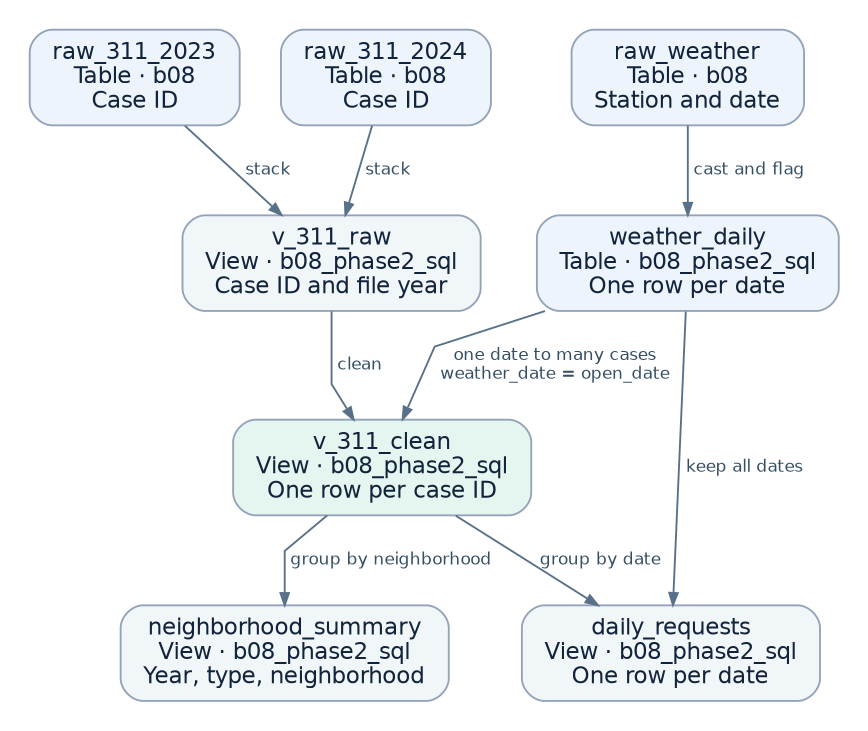

### 4.11 Column guide for `v_311_clean`

| Column | Meaning |
|---|---|
| `case_enquiry_id` | Case ID. Unique. |
| `open_dt`, `target_dt`, `closed_dt` | When the case was opened, its target date and when it was closed. `target_dt` is blank for 18% of cases and `closed_dt` for open cases and two closed cases. |
| `open_date`, `year`, `month`, `season` | From `open_dt`. Winter is Dec, Jan and Feb; Spring Mar to May; Summer Jun to Aug; Fall Sep to Nov. |
| `is_closed`, `days_to_close` | Whether the case is closed, and days from opened to closed (blank if open). |
| `target_days` | Days the City allows itself: target minus opened. |
| `has_target`, `is_on_time` | Whether the case has a target, and whether it was met. `is_on_time` is blank without a target. |
| `on_time_flag` | The City's original ONTIME / OVERDUE value. |
| `type`, `department`, `department_name` | Request type (174 values) and the department that handles it. |
| `source` | How the case was reported: Citizens Connect App, Constituent Call, Self Service, City Worker App or Employee Generated. |
| `neighborhood` | Cleaned neighborhood. Blank is `Unknown`; `Boston` is a catch-all label. |
| `ward`, `precinct`, `zipcode`, district columns, `location`, `latitude`, `longitude` | Other location fields. |
| `precip_in`, `snow_in`, `tmax_f`, `tmin_f`, `avg_wind_mph` | Weather at Logan on the day the case was opened. |
| `snow_day`, `heavy_rain_day`, `hot_day`, `cold_day`, `normal_day` | Day types from section 4.8. |

On-time rate is always `COUNTIF(is_on_time) / COUNTIF(has_target)`.

**Takeaway.** The cleaned view keeps 614,546 unique cases, including those with missing neighborhood or target fields. Every case matches one weather date.

---
## 5. Q1: Demand
*Owner: Judy*

Open cases are included here, since a request counts as demand whether or not it has been closed.

### 5.1 What are the top 10 request types each year?

In [ ]:
%%bigquery --project ba777-apr
-- Top 10 request types per year, ranked with a window function.
SELECT
  year,
  ROW_NUMBER() OVER (PARTITION BY year ORDER BY COUNT(*) DESC, type) AS rank_in_year,
  type,
  COUNT(*) AS cases,
  ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY year), 1) AS pct_of_year
FROM `ba777-apr.b08_phase2_sql.v_311_clean`
GROUP BY year, type
QUALIFY rank_in_year <= 10
ORDER BY year, rank_in_year;

year,rank_in_year,type,cases,pct_of_year
2023,1,Parking Enforcement,56813,18.5
2023,2,Mattress_Pickup,28013,9.1
2023,3,Requests for Street Cleaning,21817,7.1
2023,4,Improper Storage of Trash (Barrels),19460,6.3
2023,5,CE Collection,15420,5.0
2023,6,Schedule a Bulk Item Pickup,13287,4.3
2023,7,Missed Trash/Recycling/Yard Waste/Bulk Item,12588,4.1
2023,8,Request for Pothole Repair,11828,3.8
2023,9,Poor Conditions of Property,8225,2.7
2023,10,Needle Pickup,7413,2.4


**What it means:** Parking Enforcement is the largest type in both years, growing from 56,813 cases (18.5%) to 63,112 (20.6%). The top ten make up 60 to 63% of all requests, mostly parking, trash, street cleaning and code enforcement. Mattress_Pickup was second in 2023 but drops out of the 2024 list because no cases of that type were recorded after May 2024, so its drop doesn't show lower demand.

### 5.2 Which months and seasons have the most requests per day?

In [ ]:
%%bigquery --project ba777-apr
-- Requests per day by month opened.
SELECT
  year,
  month,
  COUNT(*) AS cases,
  ROUND(COUNT(*) / COUNT(DISTINCT open_date), 1) AS requests_per_day
FROM `ba777-apr.b08_phase2_sql.v_311_clean`
GROUP BY year, month
ORDER BY year, month;

year,month,cases,requests_per_day
2023,1,22501,725.8
2023,2,19275,688.4
2023,3,23389,754.5
2023,4,23618,787.3
2023,5,27861,898.7
2023,6,28041,934.7
2023,7,28133,907.5
2023,8,33585,1083.4
2023,9,31562,1052.1
2023,10,26232,846.2


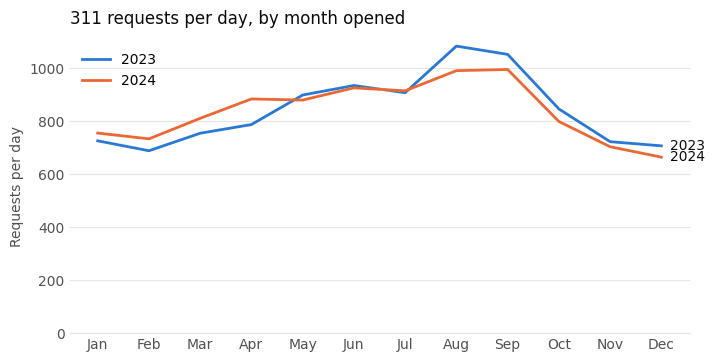

In [ ]:
%%bigquery --project ba777-apr
-- Compare average daily volume across seasons within each year.
SELECT year, season, COUNT(*) AS cases, COUNT(DISTINCT open_date) AS days,
  ROUND(COUNT(*) / COUNT(DISTINCT open_date), 1) AS requests_per_day
FROM `ba777-apr.b08_phase2_sql.v_311_clean`
GROUP BY year, season
ORDER BY year, requests_per_day DESC;

year,season,cases,days,requests_per_day
2023,Summer,89759,92,975.6
2023,Fall,79471,91,873.3
2023,Spring,74868,92,813.8
2023,Winter,63693,90,707.7
2024,Summer,86841,92,943.9
2024,Spring,78923,92,857.9
2024,Fall,75723,91,832.1
2024,Winter,65268,91,717.2


In [ ]:
%%bigquery --project ba777-apr
-- Average requests per day on weekdays and weekends. DAYOFWEEK returns 1 for Sunday and 7 for Saturday.
SELECT
  IF(EXTRACT(DAYOFWEEK FROM open_date) IN (1, 7), 'Weekend', 'Weekday') AS day_type,
  COUNT(DISTINCT open_date) AS days,
  COUNT(*) AS cases,
  ROUND(COUNT(*) / COUNT(DISTINCT open_date), 1) AS requests_per_day
FROM `ba777-apr.b08_phase2_sql.v_311_clean`
GROUP BY day_type
ORDER BY day_type;

**Takeaway.** August and September had the highest daily averages in both years. Summer averaged 975.6 requests per day in 2023 and 943.9 in 2024, compared with 707.7 and 717.2 in winter. The day of the week matters even more: weekends average 555.3 requests a day, 42% fewer than the 955.0 on weekdays. Section 8 uses this when comparing weather days.

### 5.3 How do people report issues?

In [ ]:
%%bigquery --project ba777-apr
-- How requests were reported, by year.
SELECT
  source,
  COUNTIF(year = 2023) AS cases_2023,
  ROUND(100 * COUNTIF(year = 2023) / SUM(COUNTIF(year = 2023)) OVER (), 1) AS pct_2023,
  COUNTIF(year = 2024) AS cases_2024,
  ROUND(100 * COUNTIF(year = 2024) / SUM(COUNTIF(year = 2024)) OVER (), 1) AS pct_2024
FROM `ba777-apr.b08_phase2_sql.v_311_clean`
GROUP BY source
ORDER BY cases_2024 DESC;

source,cases_2023,pct_2023,cases_2024,pct_2024
Employee Generated,113874.0,37.0,129573.0,42.2
Citizens Connect App,76797.0,25.0,79749.0,26.0
Constituent Call,78439.0,25.5,54473.0,17.8
City Worker App,29760.0,9.7,31617.0,10.3
Self Service,8919.0,2.9,11343.0,3.7
Maximo Integration,2.0,0.0,0.0,0.0


**What it means:** City staff create a large and growing share of cases. Employee Generated goes from 37.0% to 42.2%, and with the City Worker App, staff opened 46.7% of cases in 2023 and 52.5% in 2024. Phone calls fall from 78,439 (25.5%) to 54,473 (17.8%), while the Citizens Connect App stays at about a quarter. So total volume is not the same as resident demand.

### Demand takeaway

Parking Enforcement accounted for about one in five cases, and volume peaked in late summer. Track staff and resident reports separately when planning capacity.

---
## 6. Q2: Time to close and on-time rate
*Owner: Ashwin*

Two definitions apply throughout:

- **Time to close** uses closed cases only.
- **On-time rate** uses cases that have a target date. A case still open past its target counts as late.

### 6.1 How long does a request take, and how often is the target met?

In [ ]:
%%bigquery --project ba777-apr
-- Time to close and on-time rate by year, using our flag and the City flag.
SELECT
  year,
  COUNT(*) AS cases,
  ROUND(100 * COUNTIF(is_closed) / COUNT(*), 1) AS pct_closed,
  ROUND(APPROX_QUANTILES(days_to_close, 100)[OFFSET(50)], 2) AS median_days,
  ROUND(APPROX_QUANTILES(days_to_close, 100)[OFFSET(90)], 1) AS p90_days,
  ROUND(100 * COUNTIF(days_to_close <= 7) / COUNT(days_to_close), 1) AS pct_closed_within_7_days,
  ROUND(100 * COUNTIF(NOT has_target) / COUNT(*), 1) AS pct_without_target,
  ROUND(100 * COUNTIF(is_on_time) / COUNTIF(has_target), 1) AS on_time_pct,
  ROUND(100 * COUNTIF(on_time_flag = 'ONTIME') / COUNT(*), 1) AS city_flag_on_time_pct,
  ROUND(100 * COUNTIF(is_on_time) / COUNTIF(has_target AND is_closed), 1) AS on_time_pct_closed_cases_only
FROM `ba777-apr.b08_phase2_sql.v_311_clean`
GROUP BY year
ORDER BY year;

year,cases,pct_closed,median_days,p90_days,pct_closed_within_7_days,pct_without_target,on_time_pct,city_flag_on_time_pct,on_time_pct_closed_cases_only
2023,307791,93.9,0.78,22.1,78.2,20.9,75.7,80.7,79.8
2024,306755,83.7,0.53,17.2,83.6,15.9,72.0,76.5,81.2


**What it means:** Among closed cases with a recorded close time, the median is about 19 hours in 2023 and 13 hours in 2024, and about 80% of closed cases are done within a week. The slow end is long: one closed case in ten takes more than 22 days in 2023 and 17 days in 2024.

About three in four cases with a target meet it: 75.7% in 2023 and 72.0% in 2024. The City's own flag gives 80.7% and 76.5%, about 5 points higher, because it marks every case without a target (20.9% and 15.9%) as on time.

2024 is not clearly faster. Only 83.7% of 2024 cases are closed, against 93.9% in 2023, and the median leaves open cases out. Counting closed cases only, the on-time rate rises from 79.8% to 81.2%. Counting cases still open past their target, it falls. We use the second, because those cases have already missed their deadline.

In [ ]:
%%bigquery --project ba777-apr
-- 95% confidence interval for the on-time rate, normal approximation: p ± 1.96 × √(p(1 − p) / n).
WITH rates AS (
  SELECT
    year,
    COUNTIF(has_target) AS n,
    COUNTIF(is_on_time) / COUNTIF(has_target) AS p
  FROM `ba777-apr.b08_phase2_sql.v_311_clean`
  GROUP BY year
)
SELECT
  year,
  n AS cases_with_target,
  ROUND(100 * p, 2) AS on_time_pct,
  ROUND(100 * (p - 1.96 * SQRT(p * (1 - p) / n)), 2) AS ci_low_pct,
  ROUND(100 * (p + 1.96 * SQRT(p * (1 - p) / n)), 2) AS ci_high_pct
FROM rates
ORDER BY year;

**How precise is the drop?** The 95% intervals are 75.49–75.83% for 2023 and 71.86–72.21% for 2024. They do not overlap, so the 3.6-point fall is not a matter of chance variation. The interval treats each year's cases as a sample of the City's process. It does not cover recording problems: the larger uncertainty is how many 2024 open cases are unfinished rather than never closed in the system.

### 6.2 Which departments are slowest and least often on time?
Departments with at least 1,000 cases that have a target date.

In [ ]:
%%bigquery --project ba777-apr
-- Departments with at least 1,000 targeted cases, ranked by on-time rate.
SELECT
  department_name,
  COUNT(*) AS cases,
  ROUND(APPROX_QUANTILES(days_to_close, 100)[OFFSET(50)], 2) AS median_days,
  ROUND(APPROX_QUANTILES(days_to_close, 100)[OFFSET(90)], 1) AS p90_days,
  ROUND(100 * COUNTIF(NOT has_target) / COUNT(*), 1) AS pct_without_target,
  ROUND(100 * SAFE_DIVIDE(COUNTIF(is_on_time), COUNTIF(has_target)), 1) AS on_time_pct,
  ROUND(100 * SAFE_DIVIDE(COUNTIF(has_target AND is_closed AND NOT is_on_time), COUNTIF(has_target)), 1) AS closed_late_pct,
  ROUND(100 * SAFE_DIVIDE(COUNTIF(has_target AND NOT is_closed), COUNTIF(has_target)), 1) AS still_open_pct
FROM `ba777-apr.b08_phase2_sql.v_311_clean`
GROUP BY department_name
HAVING COUNTIF(has_target) >= 1000
ORDER BY on_time_pct DESC;

department_name,cases,median_days,p90_days,pct_without_target,on_time_pct,closed_late_pct,still_open_pct
Parks,36277,2.82,190.0,1.9,89.9,9.7,0.4
Public Works,328878,0.46,12.0,23.6,86.8,9.7,3.5
Inspectional Services,36747,2.86,145.1,0.5,73.3,19.8,7.0
Transportation,156761,1.02,24.3,2.3,56.3,32.6,11.1
Property Management,4519,46.94,223.0,0.1,55.7,44.3,0.0
Information Channel,24869,0.72,10.1,37.7,27.5,12.4,60.1
Water and Sewer Commission,7051,6.20,41.0,44.9,1.6,11.3,87.1


In [ ]:
%%bigquery --project ba777-apr
-- The same on-time rate split by year, with the share still open past target
SELECT
  department_name,
  ROUND(100 * SAFE_DIVIDE(COUNTIF(year = 2023 AND is_on_time), COUNTIF(year = 2023 AND has_target)), 1) AS on_time_pct_2023,
  ROUND(100 * SAFE_DIVIDE(COUNTIF(year = 2024 AND is_on_time), COUNTIF(year = 2024 AND has_target)), 1) AS on_time_pct_2024,
  ROUND(100 * SAFE_DIVIDE(COUNTIF(year = 2023 AND has_target AND NOT is_closed), COUNTIF(year = 2023 AND has_target)), 1) AS still_open_pct_2023,
  ROUND(100 * SAFE_DIVIDE(COUNTIF(year = 2024 AND has_target AND NOT is_closed), COUNTIF(year = 2024 AND has_target)), 1) AS still_open_pct_2024
FROM `ba777-apr.b08_phase2_sql.v_311_clean`
GROUP BY department_name
HAVING COUNTIF(has_target) >= 1000
ORDER BY on_time_pct_2024 DESC;

department_name,on_time_pct_2023,on_time_pct_2024,still_open_pct_2023,still_open_pct_2024
Parks,86.6,93.0,0.1,0.6
Public Works,86.2,87.3,2.7,4.2
Inspectional Services,74.3,72.3,5.2,8.6
Property Management,39.9,67.6,0.0,0.0
Transportation,64.2,48.9,1.6,19.9
Information Channel,25.9,29.0,64.0,56.7
Water and Sewer Commission,1.2,2.2,94.8,76.7


**What it means:** Parks (90%) and Public Works (87%) meet their targets most often, although about a quarter of Public Works cases have no target, mostly mattress and bulk item pickups. Transportation, which handles Parking Enforcement, is on time only 56% of the time and closes a third of its targeted cases late. Its rate falls from 64% in 2023 to 49% in 2024 as the share still open past target jumps from 1.6% to 19.9%.

Property Management, mostly graffiti removal, has the slowest median at 47 days. Water and Sewer and the Information Channel have most of their cases with a target still open (87% and 60%), so we can't tell slow service apart from closures that were never recorded.

### 6.3 Which request types are most often late?
Request types with at least 500 cases that have a target date, ranked by the share that missed it.

In [ ]:
%%bigquery --project ba777-apr
-- Request types with at least 500 targeted cases, ranked by share late.
SELECT
  type,
  COUNTIF(has_target) AS cases_with_target,
  ROUND(100 * SAFE_DIVIDE(COUNTIF(has_target AND NOT is_on_time), COUNTIF(has_target)), 1) AS late_pct,
  ROUND(100 * SAFE_DIVIDE(COUNTIF(has_target AND is_closed AND NOT is_on_time), COUNTIF(has_target)), 1) AS closed_late_pct,
  ROUND(100 * SAFE_DIVIDE(COUNTIF(has_target AND NOT is_closed), COUNTIF(has_target)), 1) AS still_open_pct,
  ROUND(APPROX_QUANTILES(target_days, 100)[OFFSET(50)], 1) AS median_target_days,
  ROUND(APPROX_QUANTILES(days_to_close, 100)[OFFSET(50)], 1) AS median_days_to_close
FROM `ba777-apr.b08_phase2_sql.v_311_clean`
GROUP BY type
HAVING COUNTIF(has_target) >= 500
ORDER BY late_pct DESC
LIMIT 10;

type,cases_with_target,late_pct,closed_late_pct,still_open_pct,median_target_days,median_days_to_close
Recycling Cart Return,7632.0,88.9,88.9,0.0,7.0,14.9
Unsafe Dangerous Conditions,786.0,82.7,73.2,9.5,1.0,12.7
Sidewalk Repair (Make Safe),11281.0,77.1,27.5,49.7,1.1,2.7
Abandoned Vehicles,9432.0,73.8,72.4,1.4,18.0,37.7
Work w/out Permit,1762.0,67.9,67.7,0.2,2.0,6.2
Protection of Adjoining Property,534.0,67.0,55.6,11.4,7.0,19.0
Building Inspection Request,1230.0,61.3,60.0,1.3,5.0,10.7
Request for Pothole Repair,22447.0,61.3,31.1,30.2,1.1,1.1
Electrical,1234.0,61.2,61.0,0.2,8.0,18.9
Contractor Complaints,2630.0,48.1,34.1,14.0,5.0,2.2


**What it means:** Recycling Cart Return is late 89% of the time: its target is 7 days and its median is 15. Abandoned Vehicles has an 18-day target and a median of about 38 days. Five building-related types handled by Inspectional Services take two to thirteen times their target; Unsafe Dangerous Conditions has a one-day target and a median of about 13 days. Nearly half of targeted sidewalk cases are still open. For potholes, 30.2% are still open and 31.1% closed late, although the median recorded closure is 1.1 days.

These are the categories to review first. The data can't say whether the cause is slow work, unrealistic targets or missing updates.

### Service speed takeaway

About three in four targeted cases met their deadlines. The rise in overdue open Transportation cases makes target misses and closure records the priority for follow-up.

---
## 7. Q3: Neighborhood gaps, 2023 vs 2024
*Owner: Zoya*

We compare neighborhoods within the same request type, using the ten largest types, so that no neighborhood looks slow just because it gets harder requests. Three rules keep the comparison fair:

- `Unknown`, `Boston` and Chestnut Hill are left out.
- A neighborhood is ranked for a type and year only if it has at least 100 cases and 30 closed cases.
- The share still open is shown next to every median.

The view below holds one row per year, request type and neighborhood.

In [ ]:
%%bigquery --project ba777-apr
-- One row per year, request type and neighborhood for the 10 largest types.
CREATE OR REPLACE VIEW `ba777-apr.b08_phase2_sql.neighborhood_summary` AS
WITH top_types AS (
  SELECT type
  FROM `ba777-apr.b08_phase2_sql.v_311_clean`
  GROUP BY type
  ORDER BY COUNT(*) DESC, type
  LIMIT 10
)
SELECT
  year,
  type,
  neighborhood,
  COUNT(*) AS cases,
  ROUND(100 * COUNTIF(NOT is_closed) / COUNT(*), 1) AS pct_still_open,
  -- Retain full precision for rankings and round for display.
  APPROX_QUANTILES(days_to_close, 100)[OFFSET(50)] AS median_days,
  APPROX_QUANTILES(days_to_close, 100)[OFFSET(90)] AS p90_days,
  COUNTIF(has_target) AS cases_with_target,
  ROUND(100 * SAFE_DIVIDE(COUNTIF(is_on_time), COUNTIF(has_target)), 1) AS on_time_pct
FROM `ba777-apr.b08_phase2_sql.v_311_clean`
JOIN top_types USING (type)
WHERE neighborhood NOT IN ('Unknown', 'Boston', 'Chestnut Hill')
GROUP BY year, type, neighborhood
HAVING COUNT(*) >= 100 AND COUNT(days_to_close) >= 30;

### 7.1 For the top 10 types, how big is the gap between the fastest and slowest neighborhood?

In [ ]:
%%bigquery --project ba777-apr
-- For each top-10 type and year, the fastest and slowest neighborhood medians.
WITH ranked AS (
  SELECT
    *,
    ROW_NUMBER() OVER (PARTITION BY year, type ORDER BY median_days, neighborhood) AS fast_rank,
    ROW_NUMBER() OVER (PARTITION BY year, type ORDER BY median_days DESC, neighborhood) AS slow_rank
  FROM `ba777-apr.b08_phase2_sql.neighborhood_summary`
)
SELECT
  type,
  year,
  COUNT(*) AS neighborhoods,
  MAX(IF(fast_rank = 1, neighborhood, NULL)) AS fastest,
  ROUND(MIN(median_days), 2) AS fastest_median_days,
  MAX(IF(slow_rank = 1, neighborhood, NULL)) AS slowest,
  ROUND(MAX(median_days), 2) AS slowest_median_days,
  ROUND(MAX(median_days) - MIN(median_days), 2) AS gap_days,
  ROUND(100 * SUM(cases * pct_still_open / 100) / SUM(cases), 1) AS pct_still_open
FROM ranked
GROUP BY type, year
ORDER BY type, year;

type,year,neighborhoods,fastest,fastest_median_days,slowest,slowest_median_days,gap_days,pct_still_open
CE Collection,2023,16,Dorchester,0.04,Charlestown,0.33,0.29,0.5
CE Collection,2024,17,Back Bay,0.04,Mission Hill,0.19,0.15,0.3
Improper Storage of Trash (Barrels),2023,17,Greater Mattapan,0.07,Mission Hill,0.24,0.16,0.3
Improper Storage of Trash (Barrels),2024,17,Greater Mattapan,0.06,Fenway / Kenmore / Audubon Circle / Longwood,0.26,0.20,0.3
Mattress_Pickup,2023,17,South Boston / South Boston Waterfront,3.03,Hyde Park,14.03,11.00,0.0
Mattress_Pickup,2024,13,South Boston / South Boston Waterfront,1.99,Hyde Park,5.89,3.90,0.0
Missed Trash/Recycling/Yard Waste/Bulk Item,2023,16,Downtown / Financial District,0.08,Allston / Brighton,0.62,0.54,0.0
Missed Trash/Recycling/Yard Waste/Bulk Item,2024,16,Downtown / Financial District,0.09,Allston / Brighton,0.59,0.50,0.0
Needle Pickup,2023,9,Roxbury,0.03,Greater Mattapan,0.04,0.01,0.0
Needle Pickup,2024,8,Roxbury,0.03,Fenway / Kenmore / Audubon Circle / Longwood,0.04,0.01,0.1


**What it means:** For six of the ten types, the fastest and slowest neighborhoods are less than 0.6 days apart in both years, among cases with a recorded closure. Larger gaps appear in Parking Enforcement (2.25 days in 2023 and 2.71 in 2024, with South Boston fastest and West Roxbury slowest) and Pothole Repair (3.90 and 2.61 days, though about 30% of pothole cases are still open). Mattress and bulk item pickups also show gaps, but their 2024 data is incomplete.

### 7.2 How long does each neighborhood wait for Parking Enforcement?
Parking Enforcement is the largest type and every case has a target, so it is the clearest test of a neighborhood gap.

In [ ]:
%%bigquery --project ba777-apr
-- Parking Enforcement medians and on-time rates by neighborhood and year.
SELECT
  neighborhood,
  MAX(IF(year = 2023, cases, NULL)) AS cases_2023,
  ROUND(MAX(IF(year = 2023, median_days, NULL)), 2) AS median_days_2023,
  MAX(IF(year = 2023, on_time_pct, NULL)) AS on_time_pct_2023,
  MAX(IF(year = 2024, cases, NULL)) AS cases_2024,
  ROUND(MAX(IF(year = 2024, median_days, NULL)), 2) AS median_days_2024,
  MAX(IF(year = 2024, on_time_pct, NULL)) AS on_time_pct_2024,
  MAX(IF(year = 2024, pct_still_open, NULL)) AS pct_still_open_2024
FROM `ba777-apr.b08_phase2_sql.neighborhood_summary`
WHERE type = 'Parking Enforcement'
GROUP BY neighborhood
ORDER BY median_days_2023 DESC;

neighborhood,cases_2023,median_days_2023,on_time_pct_2023,cases_2024,median_days_2024,on_time_pct_2024,pct_still_open_2024
West Roxbury,723,2.62,48.1,934,3.04,27.3,30.6
Hyde Park,926,1.98,51.6,1116,1.97,31.3,30.5
Roslindale,1524,1.60,56.6,1690,1.68,36.1,29.4
Jamaica Plain,2714,1.18,58.0,3972,1.86,33.9,28.8
Charlestown,2786,1.07,55.5,3036,1.05,40.7,24.1
East Boston,7187,0.99,62.1,5535,0.99,43.6,24.3
Roxbury,3101,0.91,61.9,3579,1.02,39.7,27.8
Greater Mattapan,975,0.85,63.9,1213,0.94,43.8,25.0
Back Bay,2059,0.83,63.0,2279,0.63,48.1,27.1
Dorchester,6718,0.75,66.8,6863,0.81,47.1,23.7


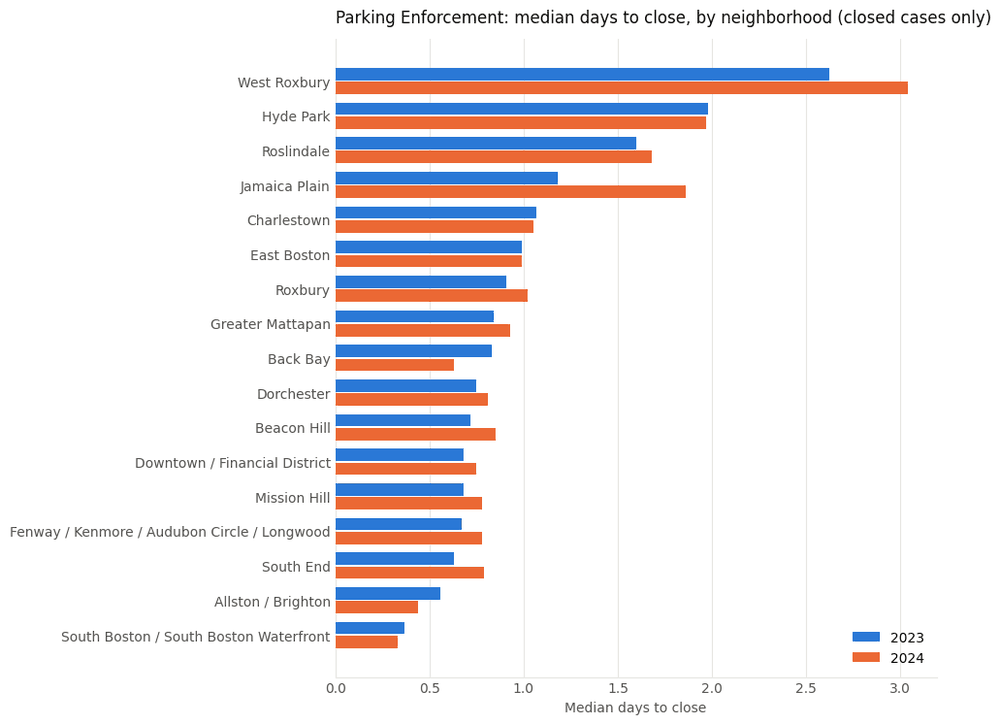

**What it means:** In 2023, when almost every parking case was closed, median recorded closure time was 0.37 days in South Boston and 2.62 days in West Roxbury, a sevenfold difference. Their on-time rates were 75.5% and 48.1%. West Roxbury, Hyde Park, Roslindale and Jamaica Plain have the four longest waits in both years. Among the neighborhoods shown, 18% to 31% of 2024 parking cases are still open. All show lower on-time rates in 2024.

**Reporter mix.** City staff may log and close parking cases differently from residents, so we check who reports them.

In [ ]:
%%bigquery --project ba777-apr
-- Share of Parking Enforcement cases opened by City staff (Employee Generated or City Worker App), by year.
SELECT
  year,
  COUNT(*) AS parking_cases,
  COUNTIF(source IN ('Employee Generated', 'City Worker App')) AS staff_reported,
  ROUND(100 * COUNTIF(source IN ('Employee Generated', 'City Worker App')) / COUNT(*), 1) AS pct_staff_reported
FROM `ba777-apr.b08_phase2_sql.v_311_clean`
WHERE type = 'Parking Enforcement'
GROUP BY year
ORDER BY year;

City staff opened 61.5% of Parking Enforcement cases in 2023 and 66.0% in 2024. The next table splits each neighborhood's median by who reported the case. A median is shown only when it rests on at least 30 closed cases.

In [ ]:
%%bigquery --project ba777-apr
-- Parking Enforcement medians split by who reported the case (residents vs City staff).
SELECT
  neighborhood,
  COUNTIF(year = 2023 AND is_resident) AS resident_cases_2023,
  IF(COUNTIF(year = 2023 AND is_resident AND is_closed) >= 30,
     ROUND(APPROX_QUANTILES(IF(year = 2023 AND is_resident, days_to_close, NULL), 100)[OFFSET(50)], 2),
     NULL) AS resident_median_2023,
  IF(COUNTIF(year = 2023 AND NOT is_resident AND is_closed) >= 30,
     ROUND(APPROX_QUANTILES(IF(year = 2023 AND NOT is_resident, days_to_close, NULL), 100)[OFFSET(50)], 2),
     NULL) AS staff_median_2023,
  IF(COUNTIF(year = 2024 AND is_resident AND is_closed) >= 30,
     ROUND(APPROX_QUANTILES(IF(year = 2024 AND is_resident, days_to_close, NULL), 100)[OFFSET(50)], 2),
     NULL) AS resident_median_2024,
  IF(COUNTIF(year = 2024 AND NOT is_resident AND is_closed) >= 30,
     ROUND(APPROX_QUANTILES(IF(year = 2024 AND NOT is_resident, days_to_close, NULL), 100)[OFFSET(50)], 2),
     NULL) AS staff_median_2024
FROM (
  SELECT
    *,
    source IN ('Citizens Connect App', 'Constituent Call', 'Self Service') AS is_resident
  FROM `ba777-apr.b08_phase2_sql.v_311_clean`
  WHERE type = 'Parking Enforcement'
    AND neighborhood NOT IN ('Unknown', 'Boston', 'Chestnut Hill')
)
GROUP BY neighborhood
ORDER BY resident_median_2023 DESC;

neighborhood,resident_cases_2023,resident_median_2023,staff_median_2023,resident_median_2024,staff_median_2024
Hyde Park,304.0,2.75,1.88,2.97,1.68
West Roxbury,305.0,2.02,2.89,2.91,3.09
Jamaica Plain,1215.0,1.77,1.02,1.93,1.80
Charlestown,923.0,1.75,0.96,1.73,0.94
Roslindale,742.0,1.60,1.60,1.72,1.52
Greater Mattapan,298.0,1.19,0.74,1.03,0.89
East Boston,3235.0,1.04,0.93,1.05,0.97
Beacon Hill,306.0,0.89,0.65,0.87,0.83
Roxbury,1268.0,0.89,0.93,1.01,1.03
Back Bay,929.0,0.83,0.83,0.64,0.63


**What it means:** The gap holds for both groups. For resident reports in 2023, medians run from 0.43 days in South Boston to 2.75 in Hyde Park. For staff reports, West Roxbury is slowest at 2.89 days. Residents file more of the reports in Jamaica Plain (45%) and Roslindale (49%) than in South Boston (26%), and the differences in closure times still appear in both reporter groups. This is not a fully controlled comparison: Hyde Park and West Roxbury have only about 300 to 440 resident cases a year.

### Neighborhood takeaway

The gap between the fastest and slowest median closure times was under 0.6 days for six of ten high-volume request types in both years. Parking Enforcement was a persistent exception, including within staff and resident reports. Check dispatch, priority and closure practices before making staffing decisions.

---
## 8. Q4: Weather vs volume and delays
*Owner: Eldo*

Weather is for the day a request was opened, measured at Boston Logan. Weather days cluster in certain months (all 17 hot days fall in June to September, when demand is already high), so each day type is compared with **normal days in the same months**.

The view below holds one row per day, with the weather and the number of requests opened.

In [ ]:
%%bigquery --project ba777-apr
-- One row per day: weather, number of requests opened and late cases.
CREATE OR REPLACE VIEW `ba777-apr.b08_phase2_sql.daily_requests` AS
SELECT
  w.weather_date,
  EXTRACT(YEAR FROM w.weather_date) AS year,
  EXTRACT(MONTH FROM w.weather_date) AS month,
  w.precip_in,
  w.snow_in,
  w.snow_day,
  w.heavy_rain_day,
  w.hot_day,
  w.cold_day,
  w.normal_day,
  COUNT(c.case_enquiry_id) AS requests,
  COUNTIF(c.has_target) AS cases_with_target,
  COUNTIF(c.has_target AND NOT c.is_on_time) AS late_cases
FROM `ba777-apr.b08_phase2_sql.weather_daily` AS w
LEFT JOIN `ba777-apr.b08_phase2_sql.v_311_clean` AS c
  ON c.open_date = w.weather_date
GROUP BY
  w.weather_date, w.precip_in, w.snow_in,
  w.snow_day, w.heavy_rain_day, w.hot_day, w.cold_day, w.normal_day;

### 8.1 Do snow, heavy rain, hot or cold days bring more requests than normal days?

In [ ]:
%%bigquery --project ba777-apr
-- Requests per day on each weather day type vs normal days in the same year and month.
WITH day_types AS (
  SELECT 'Snow' AS day_type, * FROM `ba777-apr.b08_phase2_sql.daily_requests` WHERE snow_day
  UNION ALL
  SELECT 'Heavy rain' AS day_type, * FROM `ba777-apr.b08_phase2_sql.daily_requests` WHERE heavy_rain_day
  UNION ALL
  SELECT 'Hot' AS day_type, * FROM `ba777-apr.b08_phase2_sql.daily_requests` WHERE hot_day
  UNION ALL
  SELECT 'Cold' AS day_type, * FROM `ba777-apr.b08_phase2_sql.daily_requests` WHERE cold_day
),
normal_by_month AS (
  SELECT year, month, AVG(requests) AS normal_requests_per_day
  FROM `ba777-apr.b08_phase2_sql.daily_requests`
  WHERE normal_day
  GROUP BY year, month
)
SELECT
  d.day_type,
  COUNT(*) AS days,
  ROUND(AVG(d.requests), 1) AS requests_per_day,
  ROUND(AVG(n.normal_requests_per_day), 1) AS normal_days_same_months,
  ROUND(100 * (AVG(d.requests) / AVG(n.normal_requests_per_day) - 1), 1) AS pct_difference
FROM day_types AS d
JOIN normal_by_month AS n USING (year, month)
GROUP BY d.day_type
ORDER BY pct_difference DESC;

day_type,days,requests_per_day,normal_days_same_months,pct_difference
Hot,17,1080.5,920.4,17.4
Cold,19,697.7,738.6,-5.5
Heavy rain,57,780.1,857.3,-9.0
Snow,28,625.8,746.3,-16.1


**What it means:** Only hot days are busier: about 1,080 requests a day, 17.4% more than normal days in the same months. Cold days have 5.5% fewer, heavy rain days 9.0% fewer and snow days 16.1% fewer. We match on month but not yet on weekday, and some groups are small (17 hot, 19 cold and 28 snow days). Section 8.3 adds the weekday match.

### 8.2 Are cases opened on those days more likely to be late?
Late means the case has a target and missed it, or is still open past it.

In [ ]:
%%bigquery --project ba777-apr
-- Share of targeted cases that were late, by weather day type vs normal days in the same months.
WITH day_types AS (
  SELECT 'Snow' AS day_type, * FROM `ba777-apr.b08_phase2_sql.daily_requests` WHERE snow_day
  UNION ALL
  SELECT 'Heavy rain' AS day_type, * FROM `ba777-apr.b08_phase2_sql.daily_requests` WHERE heavy_rain_day
  UNION ALL
  SELECT 'Hot' AS day_type, * FROM `ba777-apr.b08_phase2_sql.daily_requests` WHERE hot_day
  UNION ALL
  SELECT 'Cold' AS day_type, * FROM `ba777-apr.b08_phase2_sql.daily_requests` WHERE cold_day
),
normal_by_month AS (
  SELECT year, month, SUM(late_cases) / SUM(cases_with_target) AS normal_late_share
  FROM `ba777-apr.b08_phase2_sql.daily_requests`
  WHERE normal_day
  GROUP BY year, month
)
SELECT
  d.day_type,
  COUNT(*) AS days,
  SUM(d.cases_with_target) AS cases_with_target,
  ROUND(100 * SUM(d.late_cases) / SUM(d.cases_with_target), 1) AS late_pct,
  -- normal-day late share for each month, weighted by how many event-day cases fall in that month
  ROUND(
    100 * SAFE_DIVIDE(
      SUM(d.cases_with_target * n.normal_late_share),
      SUM(d.cases_with_target)
    ),
    1
  ) AS late_pct_normal_days_same_months
FROM day_types AS d
JOIN normal_by_month AS n USING (year, month)
GROUP BY d.day_type
ORDER BY late_pct DESC;

day_type,days,cases_with_target,late_pct,late_pct_normal_days_same_months
Hot,17,15194.0,29.0,26.3
Snow,28,14224.0,24.9,26.4
Heavy rain,57,35744.0,23.4,25.6
Cold,19,11534.0,22.9,29.0


**Takeaway.** Targeted cases opened on snow, heavy rain or cold days missed the target less often than on normal days in the same months. On hot days, 29.0% missed the target versus 26.3% on the baseline, a 2.7-point gap based on 17 days. The mix of request types may explain part of the difference.

### 8.3 Do the weather differences hold when weekdays are compared with weekdays?
Weekends have 42% fewer requests (section 5.2), and the weather days are not spread evenly across the week: 16 of the 17 hot days were weekdays, while 10 of the 19 cold days fell on a weekend. Here each weather day is compared with normal days in the same year, month **and** kind of day (weekday or weekend).

In [ ]:
%%bigquery --project ba777-apr
-- Repeat 8.1, matching each weather day with normal days in the same year, month and weekday/weekend group.
WITH days AS (
  SELECT *, EXTRACT(DAYOFWEEK FROM weather_date) IN (1, 7) AS is_weekend
  FROM `ba777-apr.b08_phase2_sql.daily_requests`
),
day_types AS (
  SELECT 'Snow' AS day_type, * FROM days WHERE snow_day
  UNION ALL
  SELECT 'Heavy rain' AS day_type, * FROM days WHERE heavy_rain_day
  UNION ALL
  SELECT 'Hot' AS day_type, * FROM days WHERE hot_day
  UNION ALL
  SELECT 'Cold' AS day_type, * FROM days WHERE cold_day
),
normal_baseline AS (
  SELECT year, month, is_weekend, AVG(requests) AS normal_requests_per_day
  FROM days
  WHERE normal_day
  GROUP BY year, month, is_weekend
)
SELECT
  d.day_type,
  COUNT(*) AS days,
  COUNTIF(d.is_weekend) AS weekend_days,
  ROUND(AVG(d.requests), 1) AS requests_per_day,
  ROUND(AVG(n.normal_requests_per_day), 1) AS normal_same_month_and_day_type,
  ROUND(100 * (AVG(d.requests) / AVG(n.normal_requests_per_day) - 1), 1) AS pct_difference
FROM day_types AS d
JOIN normal_baseline AS n USING (year, month, is_weekend)
GROUP BY d.day_type
ORDER BY pct_difference DESC;

**What it means:** The weekday match changes the picture. The hot-day increase shrinks from 17.4% to 2.6%, because almost all hot days were weekdays. Cold days switch from 5.5% fewer requests to 10.1% more, because half of them fell on weekends. Heavy rain (−9.6%) and snow (−16.0%) still bring fewer requests. With only 17 to 28 days in each group, these are directions to test, not effects to plan around.

### 8.4 How strongly does daily volume move with temperature and rain?
A correlation-style check across all 731 days. The second version of each correlation first subtracts the average for the same year, month and weekday/weekend group, so it reflects only day-to-day weather variation.

In [ ]:
%%bigquery --project ba777-apr
-- Pearson correlation between daily weather and daily requests, raw and after removing month and weekday/weekend averages.
WITH days AS (
  SELECT *, EXTRACT(DAYOFWEEK FROM weather_date) IN (1, 7) AS is_weekend
  FROM `ba777-apr.b08_phase2_sql.daily_requests`
),
adjusted AS (
  SELECT
    tmax_f,
    precip_in,
    requests,
    requests - AVG(requests) OVER w AS requests_vs_group_avg,
    tmax_f - AVG(tmax_f) OVER w AS tmax_vs_group_avg,
    precip_in - AVG(precip_in) OVER w AS precip_vs_group_avg
  FROM days
  WINDOW w AS (PARTITION BY year, month, is_weekend)
)
SELECT
  COUNT(*) AS days,
  ROUND(CORR(tmax_f, requests), 2) AS r_tmax_raw,
  ROUND(CORR(tmax_vs_group_avg, requests_vs_group_avg), 2) AS r_tmax_within_group,
  ROUND(CORR(precip_in, requests), 2) AS r_precip_raw,
  ROUND(CORR(precip_vs_group_avg, requests_vs_group_avg), 2) AS r_precip_within_group
FROM adjusted;

**What it means:** Across all days, warmer days have more requests (r = 0.41), but half of that is the season: within the same month and weekday group the correlation falls to 0.21. Rain has a weak negative link (r = −0.10 raw, −0.16 within group). Weather explains only a small share of day-to-day variation, so it should not be a main input for staffing.

### Weather takeaway

Weather mattered less than the calendar. After matching on month and weekday, hot days brought only 2.6% more requests, and temperature correlated with volume at r = 0.21. Snow and heavy rain days had fewer requests, and missed-target rates differed from normal days by about 3 points or less, except on cold days.

---
### Reproducibility appendix. Verify the BigQuery tables and views

This inventory checks the three source tables in `b08` and the five objects built in `b08_phase2_sql`.

In [ ]:
%%bigquery --project ba777-apr
-- List the source and report objects used by this notebook.
SELECT 'b08' AS dataset_name, table_name, table_type
FROM `ba777-apr.b08.INFORMATION_SCHEMA.TABLES`
WHERE table_name IN ('raw_311_2023', 'raw_311_2024', 'raw_weather')
UNION ALL
SELECT 'b08_phase2_sql', table_name, table_type
FROM `ba777-apr.b08_phase2_sql.INFORMATION_SCHEMA.TABLES`
WHERE table_name IN ('weather_daily', 'v_311_raw', 'v_311_clean', 'neighborhood_summary', 'daily_requests')
ORDER BY dataset_name, table_type, table_name;

dataset_name,table_name,table_type
b08,raw_311_2023,BASE TABLE
b08,raw_311_2024,BASE TABLE
b08,raw_weather,BASE TABLE
b08_phase2_sql,weather_daily,BASE TABLE
b08_phase2_sql,daily_requests,VIEW
b08_phase2_sql,neighborhood_summary,VIEW
b08_phase2_sql,v_311_clean,VIEW
b08_phase2_sql,v_311_raw,VIEW


**Takeaway.** The report uses three existing raw tables and writes one weather table and four views to the report dataset.

### Restore a missing raw table

If a raw table has been deleted, upload its CSV from Section 2 to a private US multi-region Cloud Storage bucket. Update the bucket name and run the matching load statement separately in BigQuery. Run it only for a missing table. A refreshed City extract can have different counts, dates and results.

```sql
LOAD DATA INTO `ba777-apr.b08.raw_311_2023` (
  `case_enquiry_id` STRING,
  `open_dt` STRING,
  `sla_target_dt` STRING,
  `closed_dt` STRING,
  `on_time` STRING,
  `case_status` STRING,
  `closure_reason` STRING,
  `case_title` STRING,
  `subject` STRING,
  `reason` STRING,
  `type` STRING,
  `queue` STRING,
  `department` STRING,
  `submitted_photo` STRING,
  `closed_photo` STRING,
  `location` STRING,
  `fire_district` STRING,
  `pwd_district` STRING,
  `city_council_district` STRING,
  `police_district` STRING,
  `neighborhood` STRING,
  `neighborhood_services_district` STRING,
  `ward` STRING,
  `precinct` STRING,
  `location_street_name` STRING,
  `location_zipcode` STRING,
  `latitude` STRING,
  `longitude` STRING,
  `geom_4326` STRING,
  `source` STRING
)
FROM FILES (
  format = 'CSV',
  uris = ['gs://YOUR_BUCKET_NAME/311_2023.csv'],
  skip_leading_rows = 1,
  allow_quoted_newlines = TRUE,
  max_bad_records = 0
);
```

```sql
LOAD DATA INTO `ba777-apr.b08.raw_311_2024` (
  `case_enquiry_id` STRING,
  `open_dt` STRING,
  `sla_target_dt` STRING,
  `closed_dt` STRING,
  `on_time` STRING,
  `case_status` STRING,
  `closure_reason` STRING,
  `case_title` STRING,
  `subject` STRING,
  `reason` STRING,
  `type` STRING,
  `queue` STRING,
  `department` STRING,
  `submitted_photo` STRING,
  `closed_photo` STRING,
  `location` STRING,
  `fire_district` STRING,
  `pwd_district` STRING,
  `city_council_district` STRING,
  `police_district` STRING,
  `neighborhood` STRING,
  `neighborhood_services_district` STRING,
  `ward` STRING,
  `precinct` STRING,
  `location_street_name` STRING,
  `location_zipcode` STRING,
  `latitude` STRING,
  `longitude` STRING,
  `geom_4326` STRING,
  `source` STRING
)
FROM FILES (
  format = 'CSV',
  uris = ['gs://YOUR_BUCKET_NAME/311_service_request_2024.csv'],
  skip_leading_rows = 1,
  allow_quoted_newlines = TRUE,
  max_bad_records = 0
);
```

```sql
LOAD DATA INTO `ba777-apr.b08.raw_weather` (
  `STATION` STRING,
  `NAME` STRING,
  `LATITUDE` STRING,
  `LONGITUDE` STRING,
  `ELEVATION` STRING,
  `DATE` STRING,
  `AWND` STRING,
  `AWND_ATTRIBUTES` STRING,
  `PGTM` STRING,
  `PGTM_ATTRIBUTES` STRING,
  `PRCP` STRING,
  `PRCP_ATTRIBUTES` STRING,
  `SNOW` STRING,
  `SNOW_ATTRIBUTES` STRING,
  `TAVG` STRING,
  `TAVG_ATTRIBUTES` STRING,
  `TMAX` STRING,
  `TMAX_ATTRIBUTES` STRING,
  `TMIN` STRING,
  `TMIN_ATTRIBUTES` STRING,
  `WDF2` STRING,
  `WDF2_ATTRIBUTES` STRING,
  `WDF5` STRING,
  `WDF5_ATTRIBUTES` STRING,
  `WSF2` STRING,
  `WSF2_ATTRIBUTES` STRING,
  `WSF5` STRING,
  `WSF5_ATTRIBUTES` STRING,
  `WT01` STRING,
  `WT01_ATTRIBUTES` STRING,
  `WT02` STRING,
  `WT02_ATTRIBUTES` STRING,
  `WT03` STRING,
  `WT03_ATTRIBUTES` STRING,
  `WT04` STRING,
  `WT04_ATTRIBUTES` STRING,
  `WT05` STRING,
  `WT05_ATTRIBUTES` STRING,
  `WT06` STRING,
  `WT06_ATTRIBUTES` STRING,
  `WT08` STRING,
  `WT08_ATTRIBUTES` STRING,
  `WT09` STRING,
  `WT09_ATTRIBUTES` STRING
)
FROM FILES (
  format = 'CSV',
  uris = ['gs://YOUR_BUCKET_NAME/noaa_weather_data_2023~2024.csv'],
  skip_leading_rows = 1,
  allow_quoted_newlines = TRUE,
  max_bad_records = 0
);
```

---
## 9. Conclusions and Phase 3 plan
*Owner: Almira, with input from all*

1. **Audit Transportation closures. High impact, high feasibility.** Its targeted on-time rate fell from 64.2% to 48.9% as the share still open past target rose from 1.6% to 19.9%. Compare a sample of open Parking Enforcement cases with work logs to see which requests are unfinished and which need a status update.
2. **Review targets for repeat misses. High impact, medium feasibility.** Recycling Cart Return missed its target in 89% of targeted cases, and several building-related types had median closures well past their targets. Check target definitions and work-order histories before changing deadlines.
3. **Investigate the Parking Enforcement gap. High impact, medium feasibility.** In 2023, the median recorded closure was 2.62 days in West Roxbury and 0.37 in South Boston. Collect dispatch and priority data and compare similar cases within the same shifts before reassigning crews.
4. **Plan around the calendar, not the weather. Medium impact, high feasibility.** August and September were busiest in both years, and weekends had 42% fewer requests than weekdays. Once weekday is matched, the weather effects are small (hot days +2.6%). Forecast staff and resident reports separately.

**Risks and limitations.**
- **Closure records, not work.** Close dates show when a case was closed in the system. 16.3% of 2024 cases are still open, so 2024 closure times look faster than they may be.
- **Missing targets.** 18.4% of cases have no target and are left out of on-time rates. The City's own flag counts them as on time.
- **One station, few days.** Weather comes from Logan Airport alone, and the hot, cold and snow groups have 17 to 28 days each.
- **Not controlled comparisons.** The neighborhood and weather differences are descriptive. Request mix, dispatch rules and reporter type can still explain part of them.
- **Changing data.** Results use the City files dated September 18, 2026. Later downloads will add closures and can change the numbers.

**Next steps (Phase 3).**
- Build a dashboard with volume, open cases, targeted on-time rates and neighborhood closure times. Show target coverage and the share still open with each comparison.
- Request work-order or dispatch data for Parking Enforcement and Transportation to separate unfinished jobs from missing status updates.
- Compare neighborhoods within request type, reporter type and weekday together, and add 2025 data once the City's new 311 system can be linked to the old one.

**Takeaway.** The clearest actions are an audit of Transportation's open cases and a review of repeatedly missed targets. Neighborhood and weather patterns need dispatch data before they can guide staffing.

## 10. References

- City of Boston, Boston 311. [311 Service Requests, 2023 and 2024](https://data.boston.gov/dataset/311-service-requests). [Open Data Commons Public Domain Dedication and License](https://opendatacommons.org/licenses/pddl/1-0/).
- NOAA National Centers for Environmental Information. [Daily Summaries, Boston Logan International Airport, USW00014739](https://www.ncdc.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:USW00014739/detail), January 2023 through December 2024. [GHCN-Daily documentation](https://www.ncei.noaa.gov/pub/data/ghcn/daily/readme.txt).
- Google Cloud. [Approximate aggregate functions (`APPROX_QUANTILES`)](https://cloud.google.com/bigquery/docs/reference/standard-sql/approximate_aggregate_functions) and [statistical aggregate functions (`CORR`, `STDDEV`)](https://cloud.google.com/bigquery/docs/reference/standard-sql/statistical_aggregate_functions).
- Google Cloud. [Load CSV data from Cloud Storage into BigQuery](https://cloud.google.com/bigquery/docs/loading-data-cloud-storage-csv) and [BigQuery Magics for Jupyter](https://docs.cloud.google.com/python/docs/reference/bigquery/latest/magics).

## 11. Generative AI disclosure
*Owner: Almira*

AI tools supported the project, while the team chose the questions, designed the analysis and made the final decisions. The table lists each tool and how we used it.

| Tool | How we used it |
|---|---|
| Claude (Anthropic) | Helped us understand the NOAA dataset and clarify SQL syntax, cleaning approaches and the logic of our Phase 2 questions. In the final revision, Claude reviewed the notebook against the rubric. It suggested and drafted the weekday comparison (5.2 and 8.3), the correlation query (8.4), the on-time confidence interval (6.1), the staff share of parking cases (7.2) and STDDEV/MIN in 4.5. It also drafted the risks and next steps in Section 9 and corrected one number in 7.2. |
| ChatGPT / Codex (OpenAI) | Helped with DuckDB syntax and running the SQL locally against the CSVs to check our results. In an earlier revision, Codex helped align the notebook with the rubric, update source-table references, add SQL cleaning checks and a seasonal summary, edit the text and update the diagram. |

**How we verified the work.** Each AI-drafted query was reviewed by the team and run in BigQuery, and the outputs shown are from that run. We checked row counts against the source files (614,547 raw cases), confirmed the main figures with an independent local replay of the CSVs, and checked each number in the text against the query output above it. We edited all AI-drafted text so that it matches our results.

**Takeaway.** AI helped with SQL syntax, checks and wording. The questions, the interpretation of the results and the recommendations are the team's responsibility.
